# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching, so the branching-only
`04_correlation` and `05_modules` notebooks are not produced — per the deliverable spec. The unconditional
EMT-TF step becomes the last notebook, numbered 04.)*

Overlay the data-driven EMT-transcription-factor pair on the trajectory: a categorical overlay of
thresholded expressers on a grey manifold (**not** a continuous single-gene colormap). Candidates span the
full mesenchymal-TF panel — Snail/Zeb/Twist **plus the FOXC and PRRX families** — gated on detectable
expression. VIM is a mesenchymal marker, **not** a TF, and is excluded.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
#--------------------------------------------------
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold

In [2]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 2040 | pseudotime range 0.0 -> 14.02


### Derive the end-specific EMT-TFs (data-driven, detection-gated)
For each candidate TF: fraction of cells expressing it, mean expression in the early (root) vs late
(terminus) pseudotime tercile, and Spearman correlation with pseudotime. In this SmartSeq2 CML compartment
only **ZEB1 and ZEB2** clear the 3%-detection gate (FOXC1/PRRX1/TWIST1/SNAI1 all <2% detected); both rise
toward the neural-crest terminus, so the readout is the ZEB1↔ZEB2 mesenchymal axis rather than a
root-vs-terminus pair.

In [3]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
tf_lo = ok.sort_values('rho_vs_t').iloc[0]['TF']
tf_hi = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\ndetection-gated TFs (frac>0.03): {ok.TF.tolist()} -> pair {tf_lo} <-> {tf_hi}')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 PRRX1      0.002       0.002      0.000    -0.048    EARLY(root)
TWIST1      0.003       0.012      0.002    -0.044    EARLY(root)
 FOXC1      0.007       0.003      0.004     0.006 LATE(terminus)
 SNAI1      0.019       0.025      0.055     0.084 LATE(terminus)
  ZEB1      0.233       0.250      0.481     0.173 LATE(terminus)
  ZEB2      0.425       0.528      1.324     0.267 LATE(terminus)

detection-gated TFs (frac>0.03): ['ZEB1', 'ZEB2'] -> pair ZEB1 <-> ZEB2


### EMT-TF expression overlay (deliverable `expression.pdf`)
House style: `figsize=(3.5,1.5)`, pseudotime left→right, `size=30`. Categorical overlay — cells above the
per-gene display cutoff (upper quartile among expressers) coloured on a grey manifold; the more widely
expressed factor drawn first, the sparser one on top.

overlay thresholds (upper quartile among expressers): {'ZEB1': 2.581, 'ZEB2': 3.852} | cells shown: {'ZEB1': 119, 'ZEB2': 217}
saved expression.pdf


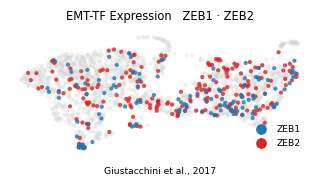

In [4]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
pair = [tf_lo, tf_hi]
thr = {}
for g in pair:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in pair}
order = sorted(pair, key=lambda g: -int(sel[g].sum()))
colors = {tf_lo:'tab:blue', tf_hi:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([],[],marker='o',ls='',color=colors[g],label=g) for g in pair],
          frameon=False, loc='lower right', fontsize=6)
ax.set_title(f'EMT-TF Expression   {tf_lo} · {tf_hi}', size=7.5)
ax.text(.5,-.14,'Giustacchini et al., 2017', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in pair},
      '| cells shown:', {g: int(sel[g].sum()) for g in pair})
print('saved expression.pdf')